<a href="https://colab.research.google.com/github/batu-uchicago/bayes-applications/blob/main/Variational%20Autoencoders/VAE_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taming the latent space: a VAE on handwritten digits

The weeks 7-9 slides build the variational autoencoder piece by piece.
Here we train one on MNIST, 70,000 pictures of handwritten digits, with a latent space of only two numbers, so that we can look at it.

- The **encoder** $g, h$ turns a picture $\mathbf{x}$ into a Gaussian over the latent space, $q(\mathbf{z}) = \mathcal{N}\bigl(\mathbf{z};\ g(\mathbf{x}),\ h(\mathbf{x})\bigr)$.
- We **sample** a $\mathbf{z}$ from it.
- The **decoder** $f$ turns $\mathbf{z}$ back into a picture, $\hat{\mathbf{x}}$.

Once the three are trained we can leave the encoder out: draw $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$, decode it, and get a digit nobody wrote.

## 1. Setup

Colab already has PyTorch, so there is nothing to install there.
Training takes a minute or two, and needs no GPU.

In [1]:
# On your laptop, `pip install -r requirements.txt` (see the README) has installed everything.
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torchvision import datasets

INK, MAROON, MUTE = "#101014", "#800000", "#6A6A72"

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training on:", device)

Training on: cpu


## 2. The data

Each picture is 28 by 28 pixels, 784 numbers between 0 (paper) and 1 (ink).
We keep one row a picture.
The labels are not used for training; we keep the test labels only to colour a plot later.

60,000 pictures to train on, 10,000 to test on, 784 pixels each


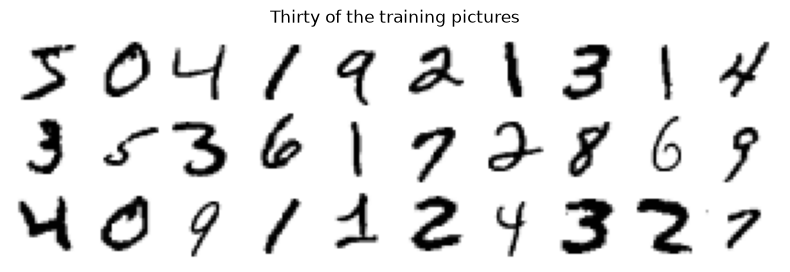

In [2]:
train_set = datasets.MNIST("data", train=True, download=True)
test_set = datasets.MNIST("data", train=False, download=True)

x_train = train_set.data.reshape(-1, 784).float().div(255).to(device)
x_test = test_set.data.reshape(-1, 784).float().div(255).to(device)
y_test = test_set.targets.numpy()
print(f"{len(x_train):,} pictures to train on, {len(x_test):,} to test on, {x_train.shape[1]} pixels each")


def tile(pictures, cols):
    # rows of 784 pixels, laid out as one image with cols pictures across
    p = pictures.detach().cpu().reshape(-1, cols, 28, 28)
    return p.permute(0, 2, 1, 3).reshape(-1, cols * 28)


def show(pictures, cols, title, width=10):
    image = tile(pictures, cols)
    plt.figure(figsize=(width, width * image.shape[0] / image.shape[1]))
    plt.imshow(image, cmap="gray_r", vmin=0, vmax=1)
    plt.title(title)
    plt.axis("off")
    plt.show()


show(x_train[:30], 10, "Thirty of the training pictures")

## 3. The model

Three pieces, as on the slide "Encoder, Sampling, Decoder":

- **Encoder.** Two layers take the 784 pixels down to 200 numbers, and two heads read them: the mean $g(\mathbf{x})$ and the log of the variance, $\ln h(\mathbf{x})^2$. The log can be any real number, so the variance comes out positive without our forcing it.
- **Sampling.** $\mathbf{z} = \mu + \sigma\,\epsilon$ with $\epsilon \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$. This is the trick of "How to Backpropagate?": the randomness sits in $\epsilon$, which has no weights, so the gradient passes through $\mu$ and $\sigma$.
- **Decoder.** The same layers in reverse, from $\mathbf{z}$ up to 784 numbers. The sigmoid at the end keeps each one between 0 and 1: it is the probability that the pixel is ink, the Bernoulli decoder of "Three Assumptions".

In [3]:
LATENT = 2      # the size of z; two, so that we can draw the latent space


class VAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.LeakyReLU(0.2),
                                     nn.Linear(400, 200), nn.LeakyReLU(0.2))
        self.mean = nn.Linear(200, latent)         # g(x)
        self.log_var = nn.Linear(200, latent)      # ln h(x)^2
        self.decoder = nn.Sequential(nn.Linear(latent, 200), nn.LeakyReLU(0.2),
                                     nn.Linear(200, 400), nn.LeakyReLU(0.2),
                                     nn.Linear(400, 784), nn.Sigmoid())

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mean(hidden), self.log_var(hidden)

    def sample(self, mean, log_var):
        sigma = torch.exp(0.5 * log_var)
        return mean + sigma * torch.randn_like(sigma)      # z = mu + sigma * epsilon

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mean, log_var = self.encode(x)
        return self.decode(self.sample(mean, log_var)), mean, log_var


model = VAE().to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} weights")

790,388 weights


## 4. The loss

The slide "Deriving the VAE Loss" ends with

$$J = -\mathbb{E}_q\bigl[\ln p(\mathbf{x} \mid \mathbf{z})\bigr] + D_{\mathrm{KL}}\bigl(q(\mathbf{z}) \parallel p(\mathbf{z})\bigr).$$

**The first term** asks for a good reconstruction.
The slides take a Gaussian decoder, which makes it a squared error.
Our pixels are between 0 and 1, so we take the Bernoulli decoder, and $-\ln p(\mathbf{x} \mid \mathbf{z})$ is the cross-entropy between the picture and its reconstruction, added over the 784 pixels.
The average over $q$ is estimated with the one $\mathbf{z}$ we sampled.

**The second term** pulls the encoder's Gaussian toward the prior $\mathcal{N}(\mathbf{0}, \mathbf{I})$.
Between two Gaussians it needs no sampling:

$$D_{\mathrm{KL}}\bigl(\mathcal{N}(\mu, \sigma^2) \parallel \mathcal{N}(\mathbf{0}, \mathbf{I})\bigr) = \tfrac{1}{2} \sum_j \bigl(\mu_j^2 + \sigma_j^2 - \ln \sigma_j^2 - 1\bigr).$$

It is zero only when $\mu = \mathbf{0}$ and $\sigma = \mathbf{1}$, that is, when the encoder ignores the picture.

In [4]:
def loss_terms(x, x_hat, mean, log_var):
    # the two terms of J, each added over the batch
    reconstruction = nn.functional.binary_cross_entropy(x_hat, x, reduction="sum")
    kl = 0.5 * torch.sum(mean ** 2 + log_var.exp() - log_var - 1)
    return reconstruction, kl

## 5. Training

Plain minibatch gradient descent with Adam, 100 pictures a step.
`beta` weighs the second term; it is 1 in $J$, and "Try it" at the end changes it.
We print the two terms for an average picture.

In [5]:
def train(model, epochs=20, beta=1.0, batch=100):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(1, epochs + 1):
        total_rec = total_kl = 0.0
        for rows in torch.randperm(len(x_train), device=device).split(batch):
            x = x_train[rows]
            rec, kl = loss_terms(x, *model(x))
            optimizer.zero_grad()
            (rec + beta * kl).backward()
            optimizer.step()
            total_rec, total_kl = total_rec + rec.item(), total_kl + kl.item()
        rec, kl = total_rec / len(x_train), total_kl / len(x_train)
        print(f"epoch {epoch:2d}: reconstruction {rec:6.1f} + KL {kl:5.2f} = {rec + kl:6.1f}")
    return model


train(model)

with torch.no_grad():
    rec, kl = loss_terms(x_test, *model(x_test))
print(f"\ntest pictures: reconstruction {rec.item() / len(x_test):6.1f} + KL {kl.item() / len(x_test):5.2f} "
      f"= {(rec + kl).item() / len(x_test):6.1f}")

epoch  1: reconstruction  176.1 + KL  4.26 =  180.4


epoch  2: reconstruction  156.5 + KL  5.15 =  161.7


epoch  3: reconstruction  152.4 + KL  5.40 =  157.8


epoch  4: reconstruction  149.3 + KL  5.59 =  154.9


epoch  5: reconstruction  147.1 + KL  5.75 =  152.9


epoch  6: reconstruction  145.6 + KL  5.82 =  151.5


... (10 outputs left out)

epoch 17: reconstruction  139.3 + KL  6.22 =  145.5


epoch 18: reconstruction  139.1 + KL  6.24 =  145.4


epoch 19: reconstruction  138.7 + KL  6.27 =  145.0


epoch 20: reconstruction  138.3 + KL  6.28 =  144.6

test pictures: reconstruction  139.1 + KL  6.37 =  145.4


The loss falls from about 180 to 145 a picture, and the test pictures, which the model never saw, score about the same.

The KL term does not go to zero; it rises, to about 6 on our run.
That is what the encoder pays to tell the pictures apart.
At zero every picture would get the same $q(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I})$, and the decoder could do no better than draw one average digit.

## 6. Reconstructions

Top row: twelve test pictures, which the model never saw.
Bottom row: what comes back when each goes through the encoder and its mean $g(\mathbf{x})$ goes through the decoder.

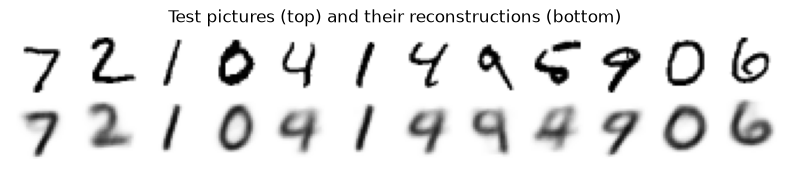

In [6]:
with torch.no_grad():
    mean, _ = model.encode(x_test[:12])
    x_hat = model.decode(mean)

show(torch.cat([x_test[:12], x_hat]), 12, "Test pictures (top) and their reconstructions (bottom)")

The reconstructions are blurry, and a few come back as another digit: on our run both 4s return looking like 9s.
Two numbers are all the decoder gets.

## 7. The latent space

Where does each test picture land?
Each dot is one picture at its mean $g(\mathbf{x})$, coloured by the digit it shows.
The dashed circles are 1, 2 and 3 standard deviations of the prior.

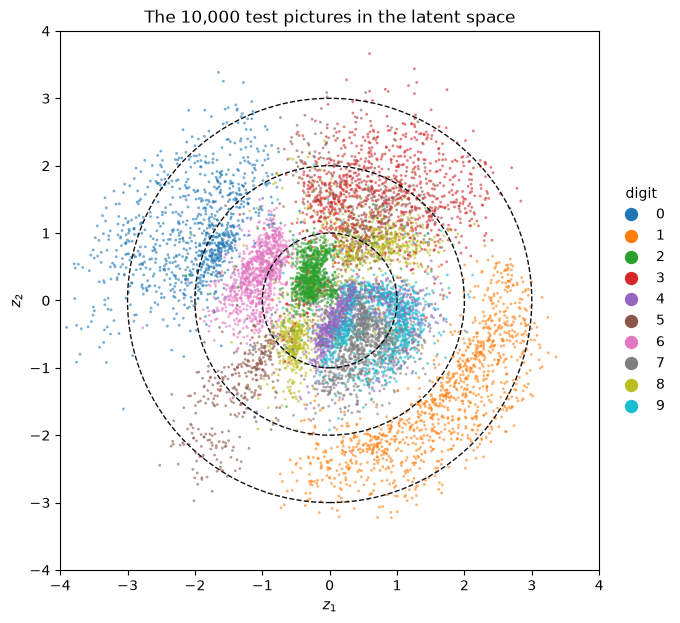

In [7]:
def plot_latent(model, limit=4):
    with torch.no_grad():
        mean, _ = model.encode(x_test)
    mean = mean.cpu().numpy()
    fig, ax = plt.subplots(figsize=(7.5, 7))
    dots = ax.scatter(mean[:, 0], mean[:, 1], c=y_test, cmap="tab10", s=4, alpha=0.6, linewidths=0)
    for radius in (1, 2, 3):
        ax.add_patch(plt.Circle((0, 0), radius, fill=False, ls="--", lw=1, color=INK))
    legend = ax.legend(*dots.legend_elements(), title="digit", loc="center left", bbox_to_anchor=(1.01, 0.5),
                       markerscale=1.6, frameon=False)
    for handle in legend.legend_handles:
        handle.set_alpha(1)
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit), aspect="equal", xlabel="$z_1$", ylabel="$z_2$",
           title="The 10,000 test pictures in the latent space")
    plt.show()


plot_latent(model)

Nobody told the model which digit is which, yet each digit has its own region: pictures that look alike land close together.
Digits that are written alike share a border; on our run 4, 7 and 9 overlap.

The cloud is packed around the origin, almost all of it within three standard deviations of the prior, and the regions touch.
That is the KL term at work, the "Desired Latent Space Behavior" of the slides: a $\mathbf{z}$ drawn from the prior lands where the decoder has been trained.

The next plot asks the decoder what it draws at each point of this square.

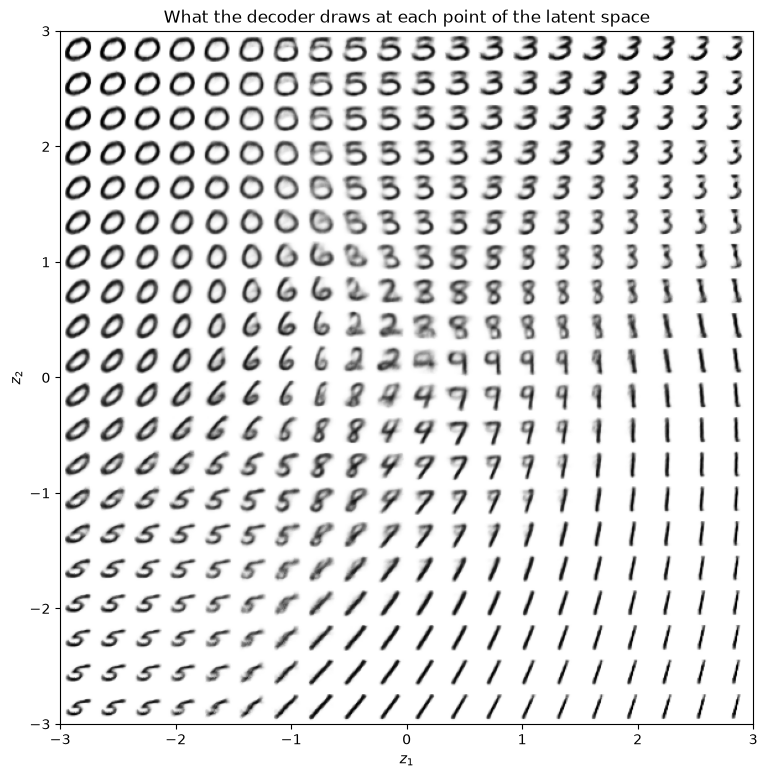

In [8]:
def plot_manifold(model, limit=3, n=20):
    # decode an n by n grid of z values, z1 across and z2 up, as in the plot above
    side = torch.linspace(-limit, limit, n)
    z1, z2 = torch.meshgrid(side, side.flip(0), indexing="xy")
    with torch.no_grad():
        pictures = model.decode(torch.stack([z1.ravel(), z2.ravel()], dim=1).to(device))
    plt.figure(figsize=(9, 9))
    plt.imshow(tile(pictures, n), cmap="gray_r", vmin=0, vmax=1, extent=[-limit, limit, -limit, limit])
    plt.xlabel("$z_1$")
    plt.ylabel("$z_2$")
    plt.title("What the decoder draws at each point of the latent space")
    plt.show()


plot_manifold(model)

Every point decodes to something close to a digit, and neighbours decode to similar pictures: walk across the space and one digit turns into another.
Hold this plot next to the dots above; the regions are the same.

## 8. New digits

Now the generative story of the slides, with no encoder and no input picture: draw $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and decode it.

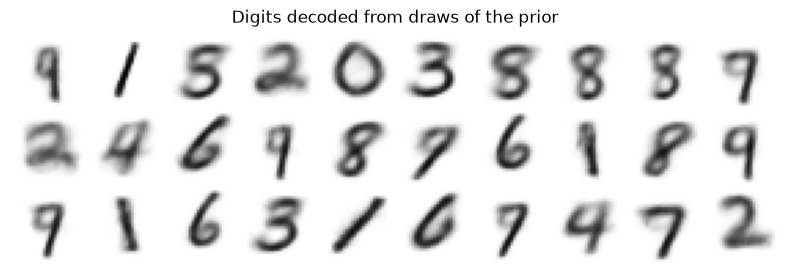

In [9]:
def plot_samples(model, count=30):
    with torch.no_grad():
        pictures = model.decode(torch.randn(count, LATENT, device=device))
    show(pictures, 10, "Digits decoded from draws of the prior")


plot_samples(model)

None of these is in the data set.
They are blurrier than handwriting, and a few sit between two digits: their $\mathbf{z}$ fell on a border.

Or choose the points yourself:

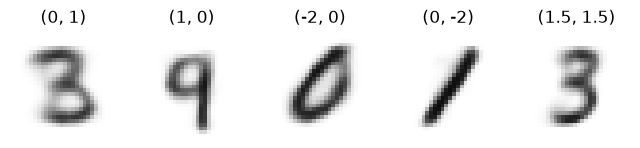

In [10]:
points = [(0.0, 1.0), (1.0, 0.0), (-2.0, 0.0), (0.0, -2.0), (1.5, 1.5)]

with torch.no_grad():
    pictures = model.decode(torch.tensor(points, device=device))

_, axs = plt.subplots(1, len(points), figsize=(1.6 * len(points), 2))
for ax, (z1, z2), picture in zip(axs, points, pictures.cpu()):
    ax.imshow(picture.reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"({z1:g}, {z2:g})")
    ax.axis("off")
plt.show()

## Try it

1. Add a point far from the prior to `points`, such as `(8.0, 8.0)`. What does the decoder draw there, and why?
2. The slide after "Software Time" shows three latent spaces. Make the first one, "Only reconstruction loss": `plain = train(VAE().to(device), beta=0)`, then `plot_latent(plain, limit=16)` and `plot_samples(plain)`. Where do the pictures land now, and which digits does a draw from the prior never give?
3. Now lean the other way, `beta=20`, which is close to "Only KL divergence". What happens to the latent space and to the reconstructions?
4. Walk from one digit to another: encode two test pictures, decode ten points on the line between their means, and `show` them.